### 1. Defining the Test Landscapes
We will define three 2D mathematical functions representing different difficulties for Hill Climbing:
1. **Local Optima (Multi-modal)**: The Ackley or Rastrigin-like function.
2. **Plateau**: A function with flat regions where gradients are zero.
3. **Ridge**: A narrow, sharp path leading uphill where coordinate-aligned steps struggle to make progress.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

# 1. Local Optima Landscape (Rastrigin-like)
def local_optima_func(x, y):
    return -(x**2 - 10 * np.cos(2 * np.pi * x) + y**2 - 10 * np.cos(2 * np.pi * y) + 20)

# 2. Plateau Landscape
def plateau_func(x, y):
    # Flat region around the outer bounds, sharp peak at the center
    r = np.sqrt(x**2 + y**2)
    if r > 2.0:
        return 0.0
    else:
        return 5.0 - 2.5 * r

# Vectorized version of plateau for plotting
def plateau_func_vec(X, Y):
    R = np.sqrt(X**2 + Y**2)
    Z = np.zeros_like(R)
    mask = R <= 2.0
    Z[mask] = 5.0 - 2.5 * R[mask]
    return Z

# 3. Ridge Landscape (Rosenbrock-like / Sharp Ridge)
def ridge_func(x, y):
    # A sharp diagonal ridge
    return -( (x - y)**2 + 0.1 * (x + y)**2 )

### 2. Standard Hill Climbing and Random Restarts Implementation
We will implement the basic first-choice hill climber and a version with random restarts.

In [2]:
def get_neighbors(state, step_size=0.1, num_neighbors=20):
    x, y = state
    neighbors = []
    for _ in range(num_neighbors):
        # Sample in a circle around the current state
        angle = random.uniform(0, 2 * np.pi)
        r = random.uniform(0, step_size)
        dx = r * np.cos(angle)
        dy = r * np.sin(angle)
        neighbors.append((x + dx, y + dy))
    return neighbors

def hill_climbing(func, bounds, start_state=None, max_iters=100, step_size=0.1):
    (min_x, max_x), (min_y, max_y) = bounds
    if start_state is None:
        current_state = (random.uniform(min_x, max_x), random.uniform(min_y, max_y))
    else:
        current_state = start_state

    current_val = func(current_state[0], current_state[1])
    trajectory = [current_state]

    for _ in range(max_iters):
        neighbors = get_neighbors(current_state, step_size)
        best_neighbor = None
        best_val = current_val

        for n in neighbors:
            # Keep neighbors within bounds
            nx = max(min_x, min(max_x, n[0]))
            ny = max(min_y, min(max_y, n[1]))
            val = func(nx, ny)
            if val > best_val:
                best_val = val
                best_neighbor = (nx, ny)

        if best_neighbor is None: # Local optimum, plateau, or ridge limit reached
            break

        current_state = best_neighbor
        current_val = best_val
        trajectory.append(current_state)

    return current_state, current_val, np.array(trajectory)

def random_restart_hill_climbing(func, bounds, num_restarts=10, max_iters=100, step_size=0.1):
    best_state = None
    best_val = -float('inf')
    all_trajectories = []

    for _ in range(num_restarts):
        state, val, traj = hill_climbing(func, bounds, None, max_iters, step_size)
        all_trajectories.append(traj)
        if val > best_val:
            best_val = val
            best_state = state

    return best_state, best_val, all_trajectories

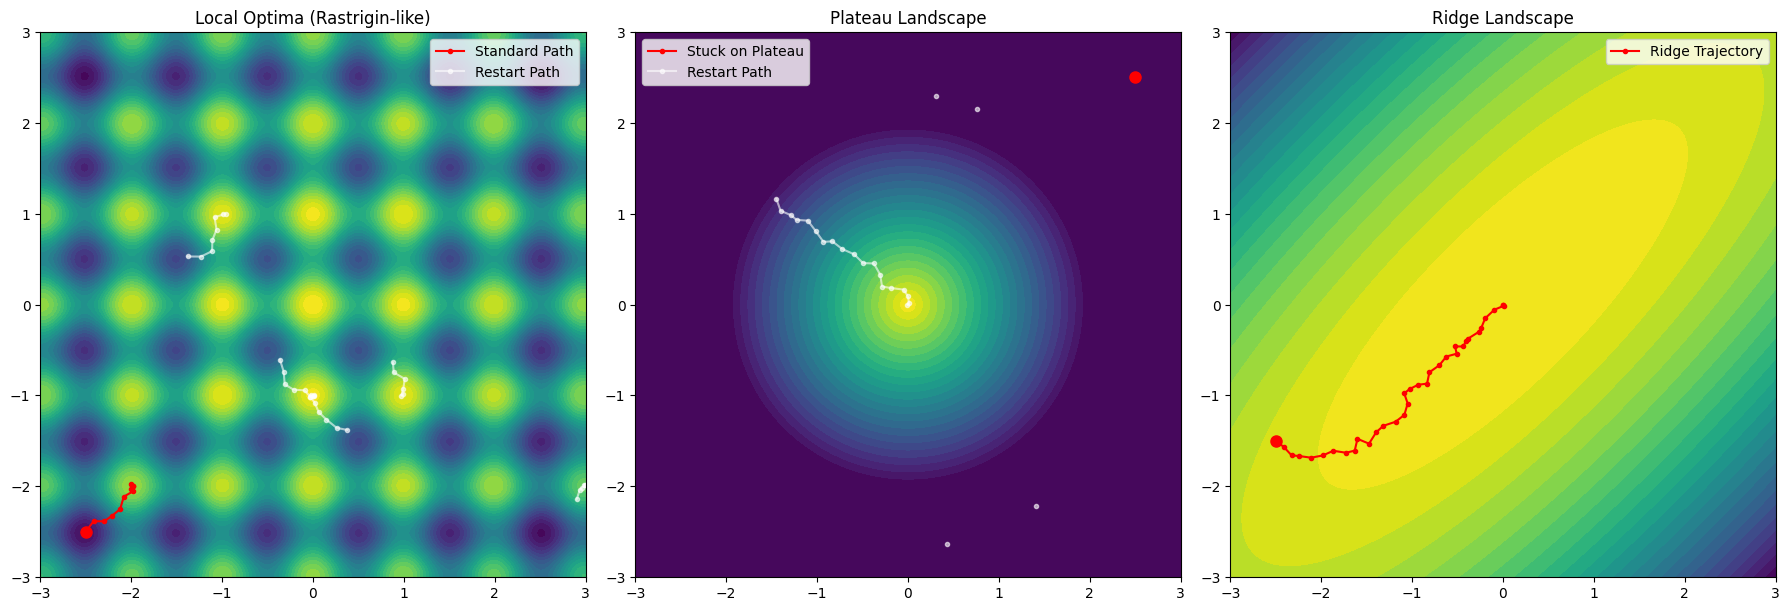

In [4]:
bounds = ((-3, 3), (-3, 3))
x_grid = np.linspace(-3, 3, 200)
y_grid = np.linspace(-3, 3, 200)
X, Y = np.meshgrid(x_grid, y_grid)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- 1. Local Optima ---
Z_local = local_optima_func(X, Y)
axes[0].contourf(X, Y, Z_local, levels=30, cmap='viridis')
axes[0].set_title('Local Optima (Rastrigin-like)')
axes[0].set_aspect('equal')  # Ensure normal, non-stretched proportions
# Standard Hill Climber (often gets stuck)
_, _, traj_std = hill_climbing(local_optima_func, bounds, start_state=(-2.5, -2.5), step_size=0.15)
axes[0].plot(traj_std[:, 0], traj_std[:, 1], 'r.-', label='Standard Path')
axes[0].plot(traj_std[0, 0], traj_std[0, 1], 'ro', markersize=8)
# Random Restart (explores different zones)
_, _, trajs_restart = random_restart_hill_climbing(local_optima_func, bounds, num_restarts=5, step_size=0.15)
for i, traj in enumerate(trajs_restart):
    axes[0].plot(traj[:, 0], traj[:, 1], 'w.-', alpha=0.6, label='Restart Path' if i == 0 else "")
axes[0].legend()

# --- 2. Plateau ---
Z_plateau = plateau_func_vec(X, Y)
axes[1].contourf(X, Y, Z_plateau, levels=30, cmap='viridis')
axes[1].set_title('Plateau Landscape')
axes[1].set_aspect('equal')  # Ensure normal, non-stretched proportions
# Start on the flat region
_, _, traj_plateau = hill_climbing(plateau_func, bounds, start_state=(2.5, 2.5), step_size=0.15)
axes[1].plot(traj_plateau[:, 0], traj_plateau[:, 1], 'r.-', label='Stuck on Plateau')
axes[1].plot(traj_plateau[0, 0], traj_plateau[0, 1], 'ro', markersize=8)
# Restart helper finding the center peak
_, _, trajs_plateau_restart = random_restart_hill_climbing(plateau_func, bounds, num_restarts=5, step_size=0.15)
for i, traj in enumerate(trajs_plateau_restart):
    axes[1].plot(traj[:, 0], traj[:, 1], 'w.-', alpha=0.6, label='Restart Path' if i == 0 else "")
axes[1].legend()

# --- 3. Ridge ---
Z_ridge = ridge_func(X, Y)
axes[2].contourf(X, Y, Z_ridge, levels=30, cmap='viridis')
axes[2].set_title('Ridge Landscape')
axes[2].set_aspect('equal')  # Ensure normal, non-stretched proportions
_, _, traj_ridge = hill_climbing(ridge_func, bounds, start_state=(-2.5, -1.5), step_size=0.15)
axes[2].plot(traj_ridge[:, 0], traj_ridge[:, 1], 'r.-', label='Ridge Trajectory')
axes[2].plot(traj_ridge[0, 0], traj_ridge[0, 1], 'ro', markersize=8)
axes[2].legend()

plt.tight_layout()
plt.show()